# Dumped furniture: outcomes and response times

What happens after someone reports dumped furniture or a mattress to 311: how the report
is closed, how long it takes, and whether the item is still there when the crew arrives.
Data: [311 Cases](https://data.sf.gov/d/vw6y-z8j6) filtered to furniture/mattress reports
(tagged since 2024-06-13), loaded and categorized by `src/sfdata/resale.py`.

- **Homeless/encampment-related reports are excluded** (about 4%): status notes mentioning
  homeless people, encampments, tents or people sleeping, or reports routed to the Healthy
  Streets Operation Center. They're about people's belongings, not dumped furniture.
- **Outcome categories come from Recology's free-text status notes** (rules in
  `resale.OUTCOMES`). Most say only "case resolved", which we read as *picked up*.
- **Recology stopped writing status notes on Aug 27, 2026.** Cases closed since then say only
  "unable to locate" or "duplicate", or nothing. So the finer categories (and the encampment
  exclusion) only work for cases closed before then; sections 1 and 5 use that period, while
  response times and "gone on arrival" use everything.
- **Time to close** is `closed_date − requested_datetime`. It's when the case was closed,
  which is usually when the crew got there.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sfdata import resale

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, SECONDARY, MUTED, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": SECONDARY,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

everything = resale.dumped_reports()
reports = everything[~everything.encampment].copy()
reports["hour"] = reports.requested.dt.hour
reports["gone"] = reports.outcome_cat.eq("Gone on arrival")
print(f"{len(everything):,} reports; {everything.encampment.sum():,} encampment-related excluded "
      f"-> {len(reports):,}")

108,352 reports; 4,314 encampment-related excluded -> 104,038


## 1. How reports are closed (cases closed before Aug 27, 2026)

94,604 reports closed while notes were still written


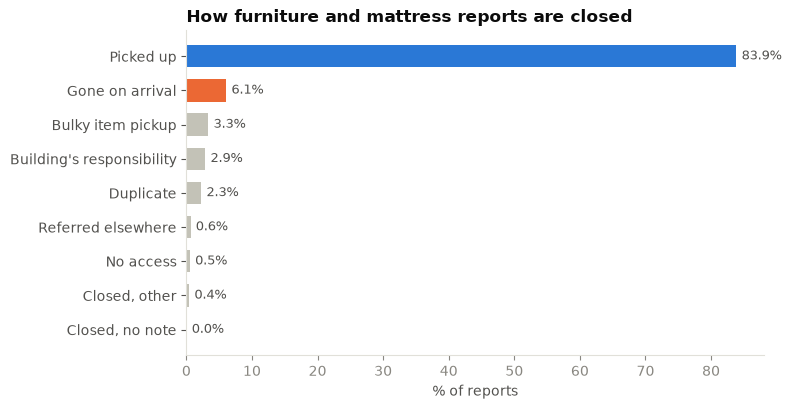

In [2]:
noted = reports[reports.has_notes_era]
print(f"{len(noted):,} reports closed while notes were still written")
shares = noted.outcome_cat.value_counts(normalize=True).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [BLUE if c == "Picked up" else ORANGE if c == "Gone on arrival" else NEUTRAL for c in shares.index]
ax.barh(shares.index, shares.values * 100, color=colors, height=0.65)
for y, v in enumerate(shares.values):
    ax.text(v * 100 + 0.8, y, f"{v:.1%}", va="center", fontsize=9, color=SECONDARY)
ax.set_xlabel("% of reports")
ax.set_title("How furniture and mattress reports are closed")
ax.tick_params(axis="y", colors=SECONDARY)
plt.tight_layout()
plt.show()

About 84% are plain pickups. The interesting minorities:

- **Gone on arrival (6%)**: the crew found nothing.
- **Bulky item pickup (3%)**: not dumping at all. Residents set items out for a scheduled
  Recology bulky-item pickup ("BIR"/"BIC" in the notes), and a neighbor reported them.
- **Building's responsibility (3%)**: items traced to a private property or apartment
  complex, which has to book (and sometimes pay for) its own pickup.

### When the notes stopped

Share of cases closed with no status note, by week closed.

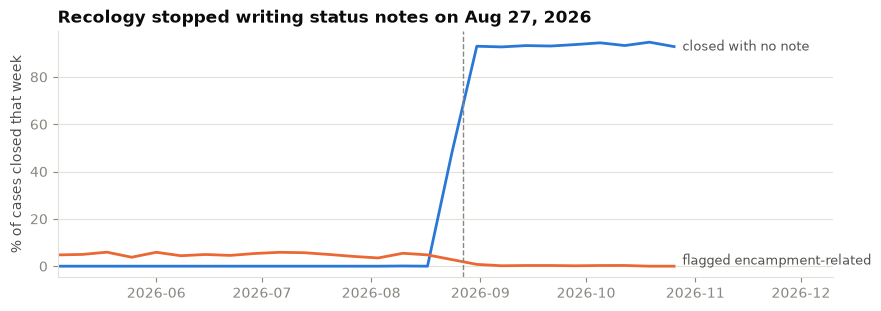

In [3]:
weekly = everything.groupby(everything.closed.dt.to_period("W")).agg(
    no_note=("outcome_cat", lambda s: (s == "Closed, no note").mean()),
    encampment=("encampment", "mean"),
)
weekly = weekly[weekly.index.start_time >= "2026-05-01"]
fig, ax = plt.subplots(figsize=(10, 3.2))
x = weekly.index.start_time
ax.plot(x, weekly.no_note * 100, color=BLUE, lw=2)
ax.plot(x, weekly.encampment * 100, color=ORANGE, lw=2)
ax.annotate("closed with no note", (x[-1], weekly.no_note.iloc[-1] * 100), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color=SECONDARY)
ax.annotate("flagged encampment-related", (x[-1], weekly.encampment.iloc[-1] * 100), xytext=(6, 4),
            textcoords="offset points", va="center", fontsize=9, color=SECONDARY)
ax.axvline(resale.NOTES_STOPPED, color=MUTED, lw=1, ls="--")
ax.set_ylabel("% of cases closed that week")
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=45))
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Recology stopped writing status notes on Aug 27, 2026")
plt.show()

## 2. The 2pm cutoff

Median time to close, by the hour the report came in.

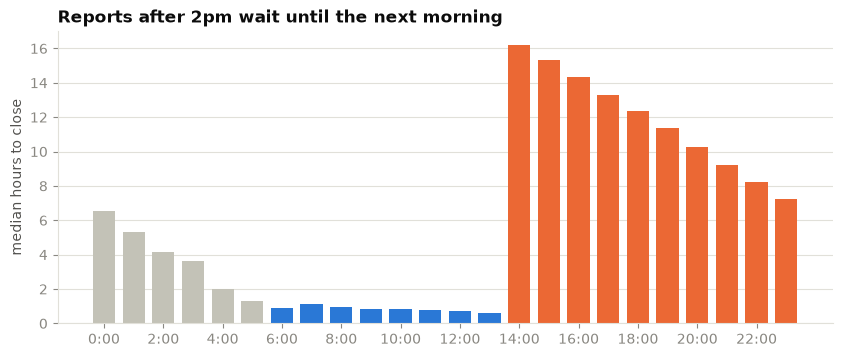

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
n,455.0,258.0,315.0,182.0,249.0,749.0,3287.0,7806.0,10885.0,10598.0,...,6319.0,6057.0,5945.0,5337.0,3997.0,2908.0,2115.0,1547.0,1026.0,636.0
median_h,6.5,5.3,4.2,3.6,2.0,1.3,0.9,1.1,0.9,0.8,...,16.2,15.3,14.3,13.3,12.3,11.4,10.2,9.2,8.2,7.3


In [4]:
by_hour = reports.groupby("hour").agg(n=("gone", "size"), median_h=("hours_to_close", "median"))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(by_hour.index, by_hour.median_h, width=0.75,
       color=[ORANGE if 14 <= h else BLUE if 6 <= h else NEUTRAL for h in by_hour.index])
ax.set_xticks(range(0, 24, 2), [f"{h}:00" for h in range(0, 24, 2)])
ax.set_ylabel("median hours to close")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Reports after 2pm wait until the next morning")
plt.show()
by_hour.T.round(1)

## 3. The longer it waits, the likelier it's gone

If people take dumped furniture, items left out longer should more often be gone. Time of day
could confound this (afternoon reports wait overnight, and the street is different at night),
so the rate is split by when the report came in.

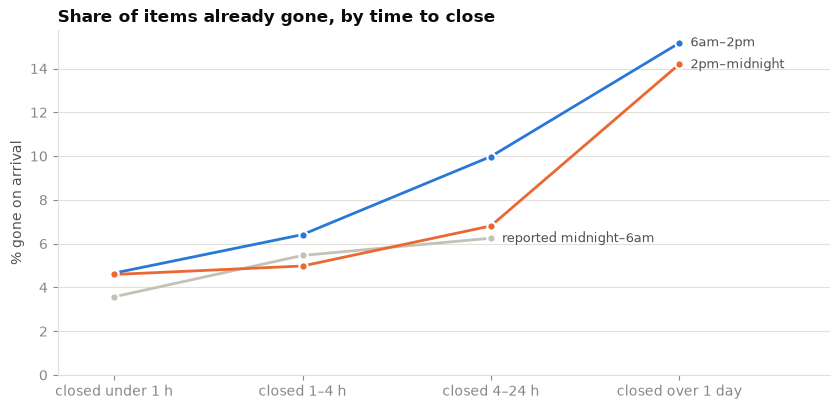

block,reported midnight–6am,6am–2pm,2pm–midnight
response,,,
under 1 h,3.6,4.7,4.6
1–4 h,5.5,6.4,5.0
4–24 h,6.2,10.0,6.8
over 1 day,5.7,15.2,14.2


block,reported midnight–6am,6am–2pm,2pm–midnight
response,,,
under 1 h,336,37728,915
1–4 h,934,23948,663
4–24 h,864,3647,33920
over 1 day,70,600,331


In [5]:
reports["block"] = pd.cut(reports.hour, [0, 6, 14, 24], right=False,
                          labels=["reported midnight–6am", "6am–2pm", "2pm–midnight"])
rates = reports.pivot_table(index="response", columns="block", values="gone", aggfunc="mean", observed=True)
counts = reports.pivot_table(index="response", columns="block", values="gone", aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(rates.index))
for col, color in zip(rates.columns, [NEUTRAL, BLUE, ORANGE]):
    ok = counts[col] >= 300  # skip thin cells
    ax.plot(x[ok], rates[col][ok] * 100, color=color, lw=2, marker="o", ms=6, mec="white", mew=1.5)
    last = np.flatnonzero(ok)[-1]
    ax.annotate(col, (x[last], rates[col].iloc[last] * 100), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=SECONDARY)
ax.set_xticks(x, [f"closed {r}" for r in rates.index])
ax.set_ylim(0, None)
ax.set_xlim(-0.3, len(x) - 0.2)
ax.set_ylabel("% gone on arrival")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Share of items already gone, by time to close")
plt.tight_layout()
plt.show()
display((rates * 100).round(1))
counts

## 4. Report source

Mobile-app reports carry a GPS location; web and phone reports are typed addresses.

In [6]:
src = reports[reports.source.isin(["Mobile", "Web", "Phone"])].groupby("source").agg(
    reports=("gone", "size"),
    gone_on_arrival=("gone", "mean"),
    median_hours=("hours_to_close", "median"),
)
src.style.format({"reports": "{:,}", "gone_on_arrival": "{:.1%}", "median_hours": "{:.1f}"})

,reports,gone_on_arrival,median_hours
source,,,
Mobile,"67,306",5.5%,1.6
Phone,"16,419",7.0%,1.6
Web,"19,328",7.2%,1.9


## 5. Over time (quarters before the notes stopped)

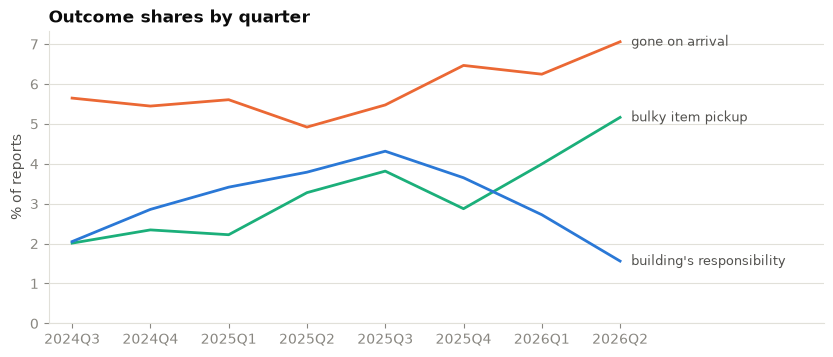

In [7]:
quarterly = noted.assign(gone=noted.outcome_cat.eq("Gone on arrival")).groupby(noted.requested.dt.to_period("Q")).agg(
    gone=("gone", "mean"),
    bulky=("outcome_cat", lambda s: (s == "Bulky item pickup").mean()),
    building=("outcome_cat", lambda s: (s == "Building's responsibility").mean()),
    n=("gone", "size"),
)
# Partial quarters out: tagging began mid-June 2024, and notes stopped partway through 2026Q3.
quarterly = quarterly[(quarterly.index > pd.Period("2024Q2")) & (quarterly.index < pd.Period("2026Q3"))]

fig, ax = plt.subplots(figsize=(10, 3.8))
x = quarterly.index.astype(str)
for col, color, label in [("gone", ORANGE, "gone on arrival"), ("bulky", AQUA, "bulky item pickup"),
                          ("building", BLUE, "building's responsibility")]:
    ax.plot(x, quarterly[col] * 100, color=color, lw=2)
    ax.annotate(label, (len(x) - 1, quarterly[col].iloc[-1] * 100), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=SECONDARY)
ax.set_ylim(0, None)
ax.set_xlim(-0.3, len(x) + 1.6)
ax.set_ylabel("% of reports")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Outcome shares by quarter")
plt.show()

## 6. By neighborhood (cases closed before Aug 27, 2026)

In [8]:
hood = noted.groupby("analysis_neighborhood").agg(
    reports=("gone", "size"),
    median_hours=("hours_to_close", "median"),
    gone_on_arrival=("gone", "mean"),
    bulky_pickup=("outcome_cat", lambda s: (s == "Bulky item pickup").mean()),
    buildings=("outcome_cat", lambda s: (s == "Building's responsibility").mean()),
)
hood = hood[hood.reports >= 500].sort_values("median_hours", ascending=False)
hood.style.format({"reports": "{:,}", "median_hours": "{:.1f}", "gone_on_arrival": "{:.1%}",
                   "bulky_pickup": "{:.1%}", "buildings": "{:.1%}"}).background_gradient(
    cmap="Blues", subset=["median_hours", "gone_on_arrival", "bulky_pickup", "buildings"])

,reports,median_hours,gone_on_arrival,bulky_pickup,buildings
analysis_neighborhood,,,,,
Chinatown,"1,117",4.7,7.8%,2.1%,0.6%
Potrero Hill,898,3.2,4.3%,9.8%,4.8%
North Beach,"1,721",3.0,8.0%,4.4%,0.5%
Mission Bay,751,2.6,9.6%,10.5%,0.8%
Bernal Heights,"2,122",2.5,2.7%,7.6%,5.7%
West of Twin Peaks,989,2.2,3.8%,2.5%,1.4%
Haight Ashbury,"3,363",2.1,5.3%,3.9%,2.3%
Inner Richmond,"2,400",2.1,2.8%,2.9%,5.3%
Lone Mountain/USF,"2,144",2.1,4.8%,3.3%,2.2%


## Observations

_Numbers as of the 2026-10-30 pull; encampment-related reports excluded._

- **There's a hard 2pm cutoff.** Reports made before 2pm are closed in a median of under an
  hour (35 minutes at 1pm). From 2pm on, the median jumps to 16 hours and then falls through
  the evening: the next morning's shift picks them up.
- **The longer an item sits, the likelier it's gone.** For reports made 6am–2pm, the "gone
  on arrival" rate goes from 4.7% (closed within an hour) to 10% (4–24 hours) to 15% (over a
  day), and afternoon reports show the same pattern. This is the strongest evidence so far that
  people take curbside furniture, though "gone" also covers items moved or reported vaguely.
- **Location precision matters too.** App reports (GPS) are gone 5.5% of the time vs about 7%
  for web and phone reports (typed addresses), with similar response times.
- **Recology stopped writing status notes on Aug 27, 2026.** Since then only "gone on arrival"
  and "duplicate" are recorded, so the finer outcomes below, and the encampment exclusion,
  only describe cases closed before that date. Encampment-related reports closed since then
  can't be identified and stay in the data.
- **About 3% of reports aren't dumping**: they're scheduled bulky-item pickups set out by
  residents, rising from about 2% in 2024 to 5% in spring 2026. It's highest in Mission Bay,
  Potrero Hill and the Financial District (8–10%). Over the same period "building's
  responsibility" fell from about 4% to under 2%; that may reflect how crews worded notes as
  much as a real change.
- **"Building's responsibility" clusters in the southeast**: Visitacion Valley (11%), Outer
  Mission and Bayview (7–8%), where items were traced back to a building that must book its own pickup.
- **"Gone on arrival" drifted up** from about 5% to 7% between 2025 and mid-2026.
- **Chinatown is the slowest neighborhood** (median 4.8 h), and the Tenderloin the fastest (1.1 h).

## Next steps

- The filterable explorer page uses these same categories (encampment-related off by default).
- Check whether the 2pm cutoff varies by season or weekday.